<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_estilingue.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: o estilingue gravitacional

## Ganhar velocidade passando perto de um planeta, e mirar o arremesso com números duais de partes complexas

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O truque das sondas.** As sondas Voyager não tinham combustível para chegar a Netuno. Elas chegaram roubando um pouquinho da energia orbital de Júpiter e de Saturno: passando perto de um planeta, a sonda é desviada pela gravidade dele. **No referencial do planeta**, nada de especial acontece: a sonda chega e sai com a mesma velocidade, só que em outra direção (a energia se conserva num campo gravitacional fixo). Mas o planeta se move em torno do Sol com velocidade $\mathbf V$, e a velocidade da sonda **no referencial do Sol** é $\mathbf u+\mathbf V$. Girar $\mathbf u$ e somar $\mathbf V$ pode aumentar (ou diminuir) o comprimento do resultado em até $2|\mathbf V|$.

**O modelo.** No referencial do planeta (massa $GM=1$, na origem), a sonda obedece a $\ddot z=-z/|z|^3$, com $z$ complexo. Durante a passagem, que é curta comparada com a órbita do planeta, $\mathbf V$ é tratado como constante (a aproximação das "esferas de influência", que as agências usam no projeto preliminar de missões).

**O problema de mira.** A sonda parte de longe, e o que se controla é a direção de chegada (o **parâmetro de impacto** $b$: a distância a que ela passaria do planeta se não houvesse gravidade). Queremos que ela saia numa direção prescrita. Isso é um problema de **tiro** (*shooting*): integrar, medir o erro de direção, corrigir $b$, repetir, por Newton. Newton precisa da derivada da direção final em relação a $b$, e a derivada sai de graça com **números duais** (notebook III(a)): integra-se a trajetória com $b+\varepsilon$, e a parte dual do resultado é a derivada.

**Um ponto de álgebra.** Aqui os números duais têm partes **complexas**: $z=z_0+\varepsilon\,z_1$, com $z_0,z_1\in\mathbb C$. É a álgebra **comutativa** $\mathbb C\otimes\mathbb D$, aquela que o notebook V(a) mostrou que **não** serve para representar poses do plano (porque poses não comutam). Para derivar, ela é perfeita: a derivada em relação a um parâmetro real comuta com tudo, inclusive com a conjugação complexa. As duas álgebras de quatro números reais, a comutativa e a não comutativa, têm cada uma o seu emprego.

**O que este notebook mostra.**
1. O integrador (RK4 com o tempo regularizado de Sundman) conserva energia, momento angular e o vetor de excentricidade: a trajetória é a hipérbole de Kepler.
2. O ganho de velocidade no referencial do Sol: passando por trás do planeta, a sonda ganha; pela frente, perde. Conferido com a fórmula da hipérbole.
3. A derivada dual da direção de saída, conferida por diferenças finitas, e o tiro de Newton.
4. A **sensibilidade**: perto do planeta, um erro minúsculo na chegada vira um desvio grande na saída.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

class Dual:
    """Número dual re + ε·du (notebook III(a)); re e du podem ser floats ou arrays."""
    __array_priority__ = 1000
    def __init__(self, re, du=0.0): self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self
    def __repr__(self): return f"{self.re} + ε·{self.du}"

def _eleva(f, df):
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
sen = _eleva(np.sin, np.cos)
cos = _eleva(np.cos, lambda a: -np.sin(a))

def conj(x):
    return Dual(np.conj(x.re), np.conj(x.du)) if isinstance(x, Dual) else np.conj(x)

def potencia(x, p):
    """x**p para x real (ou dual de partes reais)."""
    return Dual(x.re**p, p * x.re**(p - 1) * x.du) if isinstance(x, Dual) else x**p

def real(x):
    return Dual(np.real(x.re), np.real(x.du)) if isinstance(x, Dual) else np.real(x)

def campo(estado):
    """Sundman: dt = r ds.  estado = (z, u, t);  devolve (dz/ds, du/ds, dt/ds)."""
    z, u, t = estado
    r2 = real(z * conj(z)); r = potencia(r2, 0.5)
    return (u * r, -z * potencia(r2, -1.0), r)          # du/ds = r·(−z/r³) = −z/r²

def rk4(estado, ds):
    soma = lambda e, k, h: tuple(ei + h * ki for ei, ki in zip(e, k))
    k1 = campo(estado); k2 = campo(soma(estado, k1, ds / 2)); k3 = campo(soma(estado, k2, ds / 2)); k4 = campo(soma(estado, k3, ds))
    return tuple(e + ds / 6 * (a + 2 * b + 2 * c + d) for e, a, b, c, d in zip(estado, k1, k2, k3, k4))

def mod(z):
    return abs(z.re) if isinstance(z, Dual) else abs(z)

def passagem(b, u_inf=1.0, alfa=0.0, D=5000.0, ds=0.004, guarda=False):
    """A sonda chega de longe na direção alfa, com velocidade u_inf (no infinito) e parâmetro de impacto b,
    e é integrada até se afastar de novo a uma distância D. Tudo no referencial do planeta."""
    d = np.exp(1j * alfa)
    u0 = np.sqrt(u_inf**2 + 2 / D)                     # a energia u²/2 − 1/r é a do infinito
    # parte a distância D, sobre a reta de impacto, com a velocidade apontando para a frente da reta (aproximação a D grande)
    z = (-np.sqrt(D**2 - (b.re if isinstance(b, Dual) else b)**2) + 0j) * d + 1j * d * b
    u = u0 * d + 0 * b
    estado = (z, u, 0.0 * b); hist = [z]
    passou = False
    while True:
        estado = rk4(estado, ds)
        if guarda: hist.append(estado[0])
        rz = mod(estado[0])
        if rz < 100: passou = True
        if passou and rz > D: break
    return (estado, hist) if guarda else estado

## 1. A hipérbole de Kepler

No problema de dois corpos, três quantidades se conservam: a energia $E=|u|^2/2-1/|z|$, o momento angular $h=\mathrm{Im}(\bar z\,u)$ e o vetor de excentricidade $\mathbf e=\big((|u|^2-1/|z|)\,z-\mathrm{Re}(\bar z u)\,u\big)$ (em unidades com $GM=1$). Um integrador honesto tem de conservá-las a menos do erro de truncamento. A regularização de Sundman ($dt=r\,ds$) faz o passo de tempo encolher perto do planeta, onde a sonda é rápida, e crescer longe, onde ela é lenta.

In [2]:
def invariantes(z, u):
    E = abs(u)**2 / 2 - 1 / abs(z)
    h = (np.conj(z) * u).imag
    e = (abs(u)**2 - 1 / abs(z)) * z - (np.conj(z) * u).real * u
    return E, h, e

b = 2.0
(z1, u1, t1), hist = passagem(b, guarda=True)
z0, u0 = hist[0], np.sqrt(1 + 2 / 5000)
E0, h0, e0 = invariantes(hist[0], u0 + 0j)
E1, h1, e1 = invariantes(z1, u1)
print(f"{len(hist)} passos de RK4; tempo de voo {t1:.1f};  menor distância ao planeta {min(abs(z) for z in hist):.4f}")
confere("energia conservada", E1, E0, tol=1e-9)
confere("momento angular conservado", h1, h0, tol=1e-9, relativo=True)
confere("vetor de excentricidade conservado", e1, e0, tol=1e-9, relativo=True)
ecc = abs(e0); rp_teo = h0**2 / (1 + ecc)
confere("a menor distância é o periélio da hipérbole, h²/(1+e)", min(abs(z) for z in hist), rp_teo, tol=1e-3, relativo=True)
delta_teo = 2 * np.arcsin(1 / ecc)                 # deflexão da hipérbole
delta_num = np.angle(u1 / u0)
print(f"deflexão: hipérbole {np.degrees(delta_teo):.4f}°,  integração (medida a D = 5000) {np.degrees(abs(delta_num)):.4f}°")
confere("a deflexão medida longe bate com a da hipérbole (a D finito, erro da ordem de 1/D)", abs(delta_num), delta_teo, tol=1e-3)

4204 passos de RK4; tempo de voo 9988.6;  menor distância ao planeta 1.2364
OK   energia conservada:  diferença máxima = 8.99e-14
OK   momento angular conservado:  diferença relativa máxima = 4.82e-13
OK   vetor de excentricidade conservado:  diferença relativa máxima = 3.01e-11
OK   a menor distância é o periélio da hipérbole, h²/(1+e):  diferença relativa máxima = 2.50e-06
deflexão: hipérbole 53.1209°,  integração (medida a D = 5000) 53.1209°
OK   a deflexão medida longe bate com a da hipérbole (a D finito, erro da ordem de 1/D):  diferença máxima = 7.99e-08


## 2. O ganho de velocidade no referencial do Sol

O planeta se move para a direita com $\mathbf V=1$ (a mesma escala da velocidade da sonda). A sonda chega de baixo, subindo ($\alpha=90°$), e a sua velocidade no referencial do Sol é $u+V$. Pela hipérbole, a velocidade de saída no planeta é a de chegada girada de $\pm\delta$ (o sinal depende do lado por onde a sonda passa), e o ganho é

$$\Delta v=|u_\infty e^{i(\alpha\pm\delta)}+V|-|u_\infty e^{i\alpha}+V|.$$

Para $b>0$, a sonda passa à esquerda do planeta, isto é, **por trás** dele (o planeta vai para a direita): ela é puxada no sentido do movimento do planeta, e ganha. Para $b<0$, passa pela frente, e perde.

In [3]:
V, ALFA = 1.0 + 0j, np.pi / 2
bs = np.array([-6, -4, -3, -2, -1.5, -1, -0.6, 0.6, 1, 1.5, 2, 3, 4, 6])
ganho_num, ganho_teo = [], []
for b in bs:
    z1, u1, t1 = passagem(b, alfa=ALFA)
    u_saida = u1 / abs(u1) * 1.0                     # velocidade "no infinito" (a energia dá o módulo; a direção é a medida a D)
    ganho_num.append(abs(u_saida + V) - abs(np.exp(1j * ALFA) + V))
    ecc = np.sqrt(1 + b**2)                          # com u_inf = 1 e GM = 1: e² = 1 + b² u⁴
    delta = 2 * np.arcsin(1 / ecc) * np.sign(b)      # b > 0: o planeta fica à direita da sonda, que é desviada no sentido horário (−δ)
    ganho_teo.append(abs(np.exp(1j * (ALFA - delta)) + V) - abs(np.exp(1j * ALFA) + V))
ganho_num, ganho_teo = np.array(ganho_num), np.array(ganho_teo)
for b, gn, gt in zip(bs, ganho_num, ganho_teo):
    print(f"b = {b:+5.1f}:  ganho no referencial do Sol {gn:+.4f}  (hipérbole {gt:+.4f})")
confere("o ganho medido bate com a fórmula da hipérbole", ganho_num, ganho_teo, tol=2e-3)
confere("passando por trás (b > 0) ganha, pela frente (b < 0) perde", [np.all(ganho_num[bs > 0] > 0), np.all(ganho_num[bs < 0] < 0)], [True, True])
print(f"o maior ganho possível, com deflexão de 180°, seria 2V = 2;  aqui o maior foi {ganho_num.max():.3f}")

b =  -6.0:  ganho no referencial do Sol -0.2517  (hipérbole -0.2517)
b =  -4.0:  ganho no referencial do Sol -0.3851  (hipérbole -0.3852)
b =  -3.0:  ganho no referencial do Sol -0.5197  (hipérbole -0.5198)
b =  -2.0:  ganho no referencial do Sol -0.7816  (hipérbole -0.7818)
b =  -1.5:  ganho no referencial do Sol -1.0218  (hipérbole -1.0220)
b =  -1.0:  ganho no referencial do Sol -1.4140  (hipérbole -1.4142)
b =  -0.6:  ganho no referencial do Sol -0.9293  (hipérbole -0.9291)
b =  +0.6:  ganho no referencial do Sol +0.5261  (hipérbole +0.5261)
b =  +1.0:  ganho no referencial do Sol +0.5858  (hipérbole +0.5858)
b =  +1.5:  ganho no referencial do Sol +0.5469  (hipérbole +0.5469)
b =  +2.0:  ganho no referencial do Sol +0.4831  (hipérbole +0.4832)
b =  +3.0:  ganho no referencial do Sol +0.3746  (hipérbole +0.3746)
b =  +4.0:  ganho no referencial do Sol +0.3007  (hipérbole +0.3008)
b =  +6.0:  ganho no referencial do Sol +0.2132  (hipérbole +0.2133)
OK   o ganho medido bate com a fór

## 3. A derivada dual e o tiro

Agora a mira. A sonda chega como antes ($\alpha=90°$, $u_\infty=1$), e queremos que ela saia, no referencial do Sol, na direção de $30°$ (rumo a um planeta mais externo). A incógnita é o parâmetro de impacto $b$. Função: $g(b)=\arg(u_{\text{saída}}+V)-30°$. Para Newton, $g'(b)$: a integração inteira roda com $b=b_0+\varepsilon$, e $g'$ sai da parte dual do resultado (a parte dual de $\arg w$ é $\mathrm{Im}(\dot w/w)$).

O laço do integrador tem um teste de parada (`rz > D`) que usa só a parte real: a derivada é a da trajetória com o **mesmo número de passos**, o que é correto enquanto o último passo não mudar de lugar (a derivada do instante de parada é desprezível a $D=5000$, onde a sonda já anda em linha reta).

In [4]:
ALVO = np.radians(30)

def g_e_derivada(b):
    z1, u1, t1 = passagem(Dual(b, 1.0), alfa=ALFA)
    w = u1 + V                                       # velocidade no referencial do Sol (dual de partes complexas)
    return np.angle(w.re) - ALVO, (w.du / w.re).imag

def g(b):
    z1, u1, t1 = passagem(b, alfa=ALFA)
    return np.angle(u1 + V) - ALVO

b0 = 1.5
val, der = g_e_derivada(b0)
h = 1e-5
der_df = (g(b0 + h) - g(b0 - h)) / (2 * h)
print(f"g({b0}) = {np.degrees(val):+.4f}°;  g'(b) dual = {der:.8f} rad por unidade;  diferenças finitas {der_df:.8f}")
confere("derivada dual = diferenças finitas", der, der_df, tol=1e-6, relativo=True)

b = 3.0
for it in range(8):
    val, der = g_e_derivada(b)
    print(f"it {it}: b = {b:.10f},  direção de saída − alvo = {np.degrees(val):+.3e}°")
    if abs(val) < 1e-12: break
    b -= val / der
confere("o tiro de Newton acerta a direção de saída", g(b), 0, tol=1e-10)
b_tiro = b

g(1.5) = -18.6836°;  g'(b) dual = 0.30768213 rad por unidade;  diferenças finitas 0.30768213
OK   derivada dual = diferenças finitas:  diferença relativa máxima = 2.01e-11
it 0: b = 3.0000000000,  direção de saída − alvo = -3.429e+00°


it 1: b = 3.5986126248,  direção de saída − alvo = -5.236e-01°
it 2: b = 3.7261569810,  direção de saída − alvo = -1.649e-02°


it 3: b = 3.7304426064,  direção de saída − alvo = -4.479e-06°
it 4: b = 3.7304437730,  direção de saída − alvo = -1.565e-12°
OK   o tiro de Newton acerta a direção de saída:  diferença máxima = 2.73e-14


## 4. Sensibilidade: o preço de passar perto

Quanto mais perto do planeta a sonda passa (menor $|b|$), maior a deflexão e maior a **sensibilidade**: a derivada $\partial(\text{direção de saída})/\partial b$ cresce. Para a hipérbole, a deflexão no referencial do planeta é $\delta=2\arctan(1/b)$ (com $GM=u_\infty=1$), e $|\partial\delta/\partial b|=2/(1+b^2)$, que vale no máximo 2 radianos por unidade de $b$. A derivada dual mede a sensibilidade da direção no referencial do Sol, que é o que interessa para a navegação.

b =  0.3:  ∂(direção no Sol)/∂b =   +0.9177 rad/unidade;   |∂δ/∂b| no referencial do planeta = 1.8349
b =  0.5:  ∂(direção no Sol)/∂b =   +0.8002 rad/unidade;   |∂δ/∂b| no referencial do planeta = 1.6000
b =  1.0:  ∂(direção no Sol)/∂b =   +0.5000 rad/unidade;   |∂δ/∂b| no referencial do planeta = 1.0000
b =  2.0:  ∂(direção no Sol)/∂b =   +0.2000 rad/unidade;   |∂δ/∂b| no referencial do planeta = 0.4000
b =  4.0:  ∂(direção no Sol)/∂b =   +0.0588 rad/unidade;   |∂δ/∂b| no referencial do planeta = 0.1176
b =  8.0:  ∂(direção no Sol)/∂b =   +0.0154 rad/unidade;   |∂δ/∂b| no referencial do planeta = 0.0308
OK   a sensibilidade cai quando a passagem é mais distante:  diferença máxima = 0.00e+00
OK   com u∞ = V, a direção no Sol gira exatamente metade do que gira a direção no planeta:  diferença relativa máxima = 3.28e-04


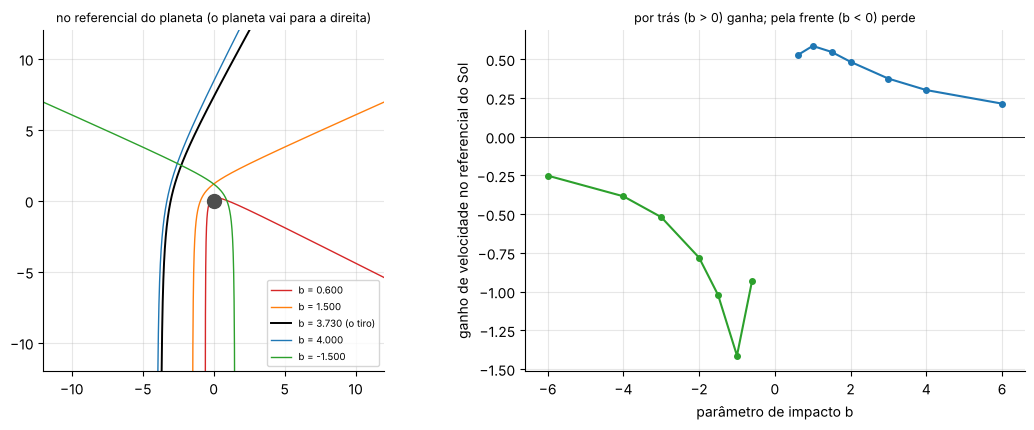

In [5]:
bs_s = np.array([0.3, 0.5, 1.0, 2.0, 4.0, 8.0])
sens = np.array([g_e_derivada(b)[1] for b in bs_s])
teo = np.array([2 / (1 + b**2) for b in bs_s])     # deflexão no planeta: δ = 2 arcsin(1/√(1+b²)) = 2 arctan(1/b);  dδ/db = −2/(1+b²)
for b, s_, t_ in zip(bs_s, sens, teo):
    print(f"b = {b:4.1f}:  ∂(direção no Sol)/∂b = {s_:+9.4f} rad/unidade;   |∂δ/∂b| no referencial do planeta = {t_:.4f}")
confere("a sensibilidade cai quando a passagem é mais distante", np.all(np.diff(np.abs(sens)) < 0), True)
confere("com u∞ = V, a direção no Sol gira exatamente metade do que gira a direção no planeta", np.abs(sens), teo / 2, tol=1e-3, relativo=True)   # a D finito, a sonda ainda é um pouco mais rápida que u∞

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axs[0]
for b, cor in [(0.6, "C3"), (1.5, "C1"), (b_tiro, "k"), (4.0, "C0"), (-1.5, "C2")]:
    _, hist = passagem(b, alfa=ALFA, D=40.0, guarda=True)
    hist = np.array(hist)
    ax.plot(hist.real, hist.imag, color=cor, lw=1.4 if cor == "k" else 1, label=f"b = {b:.3f}" + (" (o tiro)" if cor == "k" else ""))
ax.plot(0, 0, "o", color="0.3", ms=10); ax.set_xlim(-12, 12); ax.set_ylim(-12, 12); ax.set_aspect("equal")
ax.set_title("no referencial do planeta (o planeta vai para a direita)", fontsize=9); ax.legend(fontsize=7)
ax = axs[1]
ax.plot(bs[bs < 0], ganho_num[bs < 0], "o-", ms=4, color="C2"); ax.plot(bs[bs > 0], ganho_num[bs > 0], "o-", ms=4, color="C0")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("parâmetro de impacto b"); ax.set_ylabel("ganho de velocidade no referencial do Sol")
ax.set_title("por trás (b > 0) ganha; pela frente (b < 0) perde", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** O RK4 com o tempo de Sundman conserva energia e momento angular até $10^{-13}$ e o vetor de excentricidade até $10^{-11}$, com uns 4 mil passos para uma viagem de 10 mil unidades de tempo, e a menor distância e a deflexão batem com as da hipérbole. O ganho de velocidade no referencial do Sol confere com a fórmula da hipérbole (a menos de $2\times10^{-4}$, o efeito de medir a direção a uma distância finita): passando por trás do planeta a sonda ganha até $0{,}59$ (em $b=1$), passando pela frente perde até $1{,}41$. O ganho máximo teórico, $2V$, exigiria uma deflexão de 180°, impossível com o planeta tendo tamanho.

A derivada dual da direção de saída coincide com as diferenças finitas em 11 algarismos, e o tiro de Newton converge quadraticamente em quatro iterações ($b=3{,}7304$). A sensibilidade tem uma explicação de geometria: com $u_\infty=V$, a velocidade no referencial do Sol é a soma de dois vetores de mesmo comprimento, que aponta para a bissetriz deles, e por isso gira exatamente metade do que gira $u$; a derivada dual confere isso a menos de $4\times10^{-4}$ (a diferença vem de medir a sonda a uma distância finita, onde ela ainda é um pouco mais rápida que no infinito).

A sensibilidade em si é modesta (no máximo 1 radiano por unidade de $b$, aqui), mas a escala engana. Para Júpiter, com $u_\infty=10$ km/s, a unidade de comprimento $GM/u_\infty^2$ vale cerca de 1,3 milhão de km. Um erro de 100 km na chegada é $8\times10^{-5}$ unidades, e desvia a saída de uns $10^{-4}$ rad; depois de viajar 1 unidade astronômica (150 milhões de km), isso vira mais de 10 mil km de erro. É por isso que as sondas fazem **manobras de correção de trajetória** antes e depois de cada passagem, e por isso o cálculo das derivadas, que a navegação usa o tempo todo, precisa ser exato e barato: é o que os duais entregam.

## Exercícios

1. **A derivada do tempo de voo.** O estado final traz o tempo $t$ também como dual. O que significa a sua parte dual? Confira por diferenças finitas.
2. **Duas incógnitas.** Libere também a velocidade de chegada $u_\infty$ e peça, além da direção de saída, uma velocidade de saída prescrita no referencial do Sol. Agora são duas integrações duais por iteração (uma para cada derivada parcial), e o jacobiano é $2\times2$.
3. **Passar pela frente para frear.** A sonda Messenger, a caminho de Mercúrio, usou passagens pela Terra e por Vênus para **perder** energia orbital. Encontre o $b$ que reduz ao máximo a velocidade no referencial do Sol, sem chegar a menos de $0{,}2$ do centro do planeta.